# 03. Lead-window difference maps

## Purpose

Show where ERA5 + CLIM_BASE aerosol and ozone initialization differs from the ERA5 initialization of HYB_BASE (`clim_fill` = ERA5_CLIMFILL − ERA5_BARE, member EN01), as lead-window means (days 1-3, 4-10, 11-28, 29-56). Stippling marks gridpoints where |A − B| exceeds twice the noise scale (√2 × the gridpoint spread of the 20 HYB_BASE members in that window), so only differences that member-to-member chaos alone is unlikely to produce are marked. Section 6 does the same for the ozone, CO and aerosol fields that only the monthly `eam.h0` files carry (calendar-month windows).

**Focus: ERA5 + CLIM_BASE aerosol and ozone initialization vs the ERA5 initialization (HYB_BASE), same member.** Both runs start on 16 Dec 2011 00Z from member EN01: the same ERA5 state with the same DART perturbation EN01, over the same DATM-forced land EN01. HYB_BASE EN01 (`ERA5_BARE`) uses the ERA5 file as it is. It holds only T, U, V, Q, PS, CLDLIQ and CLDICE, and EAM starts every missing field from zero: the aerosols, ozone and the other radiative gases (`rad_climate` reads H2OLNZ, O3, N2OLNZ and CH4LNZ), and the hydrometeor numbers. `ERA5_CLIMFILL` keeps those ERA5 fields unchanged and takes every missing field from the free-running CLIM_BASE (FREE_CLIM) state of the same date (`ensemble_perturbations/util/complete_era5_ic.py`; H2OLNZ follows the ERA5 Q). The comparison `clim_fill` = ERA5_CLIMFILL − ERA5_BARE is therefore the effect of initializing aerosols, ozone and the other missing fields.

A single-member difference is judged against `ev.noise_scale`: √2 × the member spread of the 20 HYB_BASE members of the same start (`ENSEMBLE_RUN`), the chaotic divergence of two members of that ensemble. The other tests (`ERA5_DARTFILL`, `CLIMO_ATM`, `CLIMO_LND`) and production runs remain in `configs/hind_ic_test_runs.py` and can be added to `RUN_KEYS`, `PLOT_GROUPS` and `COMPARISON_KEYS`.

## Inputs and outputs

Model and ensemble daily fields as in notebook 02. Outputs: `data/hind_ic_test/maps/window_maps_<VAR>.nc` (differences and noise scale by comparison and window); figures `figure/hind_ic_test/maps/maps_<VAR>.png` (rows: windows; columns: comparisons). Monthly `eam.h0` fields (section 6): `data/.../h0_maps_<VAR>.nc`, figures `maps_<VAR>_monthly.png` and, for ozone, the zonal-mean section `zonal_O3_monthly.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


## 2. User setup

Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")            # production F20TR hindcasts
TEST_DATA_ROOT = Path("/pscratch/sd/z/zhan391/e3sm_dart/simulation")             # the test runs
IC_ROOT = Path("/global/cfs/cdirs/m4849/zhan391")                                  # initial-file library (DART_INIT/, e3sm_dart/)
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                     # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"
ATM_MAP_FILE = Path("/global/cfs/cdirs/e3sm/diagnostics/maps/map_ne30pg2_to_cmip6_180x360_aave.20200201.nc")  # same weights as regen_f20tr_ts.sh
WORKFLOW_NAME = "hind_ic_test"

RUN_KEYS = ("ERA5_BARE", "ERA5_CLIMFILL")          # HYB_BASE EN01 and ERA5 + CLIM_BASE fill EN01 (configs/hind_ic_test_runs.py)
ENSEMBLE_RUN = "ERA5_BARE"         # HYB_BASE, 20 members
MAX_MEMBERS = None
MAX_LEAD = 56
COMPARISON_KEYS = ("clim_fill",)
VARIABLES = ("TREFHT", "T850", "TOZ", "FSDSC", "FLDS", "SWCF", "LWCF", "PRECT")
WINDOWS = {"days 1-3": (1, 3), "days 4-10": (4, 10), "days 11-28": (11, 28), "days 29-56": (29, 56)}
# shading limits per variable (symmetric); others use the 98th percentile of |A - B|
LIMITS = {"TREFHT": 6.0, "T850": 4.0, "TOZ": 300.0, "FSDSC": 20.0, "FLDS": 40.0, "SWCF": 120.0, "LWCF": 60.0, "PRECT": 4.0}
# monthly eam.h0 fields (section 6): O3 as a zonal-mean section, the rest as maps; CH4LNZ is in no history stream
H0_VARIABLES = ("O3", "O3_SRF", "CO_SRF", "AODVIS")
H0_LIMITS = {"O3": 100.0, "O3_SRF": 48.0, "CO_SRF": 120.0, "AODVIS": 0.3}   # O3: % of run A
TOPIC = "maps"
FORCE_COMPUTE = False
FIGURE_DPI = 150
SHOW = True

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from util import hind_ic_test_eval as ev
from configs.hind_ic_test_runs import COMPARISONS, GROUPS, INIT, RUNS, check_runs, ensemble_members, member_dir
from util.hind_case_io import cached_dataset, cached_table, figure_saver

check_runs(RUN_KEYS)
ROOTS = {"test": TEST_DATA_ROOT, "production": INPUT_DATA_ROOT}
data_dir = DIAGNOSTIC_OUTPUT_ROOT / "data" / WORKFLOW_NAME / TOPIC
figure_dir = DIAGNOSTIC_OUTPUT_ROOT / "figure" / WORKFLOW_NAME / TOPIC
data_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
save = figure_saver(figure_dir, dpi=FIGURE_DPI, show=SHOW)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

runs = pd.DataFrame([dict(run=k, case=f"{r.case}_{INIT.astype(object):%Y%m%d}00", member=r.member, source=r.source,
                          atmosphere=r.atm_ic, land=r.lnd_ic) for k, r in RUNS.items() if k in RUN_KEYS]).set_index("run")
display(runs)
display(pd.DataFrame([dict(comparison=k, A=a, B=b, question=q) for k, (a, b, q) in COMPARISONS.items()]).set_index("comparison"))

unknown = [c for c in COMPARISON_KEYS if c not in COMPARISONS]
if unknown:
    raise KeyError(f"unknown comparisons {unknown}; choose from {list(COMPARISONS)}")
ens_members = ensemble_members(RUNS[ENSEMBLE_RUN].case, INIT, ROOTS[RUNS[ENSEMBLE_RUN].source])[:MAX_MEMBERS]
paths = {k: member_dir(k, ROOTS) for k in RUN_KEYS}
print(f"[ENSEMBLE] {ENSEMBLE_RUN}: {len(ens_members)} members")

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps


,case,member,source,atmosphere,land
run,,,,,
ERA5_BARE,F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_2011...,EN01,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DATM EN01
ERA5_CLIMFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5CLIMFILL_...,EN01,test,ERA5 + CLIM_BASE fields,DATM EN01


,A,B,question
comparison,,,
clim_fill,ERA5_CLIMFILL,ERA5_BARE,ERA5 + CLIM_BASE aerosol and ozone initializat...
tracer_fix,ERA5_DARTFILL,ERA5_BARE,Does completing the ERA5 state remove the cold...
fill_source,ERA5_CLIMFILL,ERA5_DARTFILL,Does the source of the filled fields matter? (...
atm_clim,CLIMO_ATM,DA_COUPLED,"Atmosphere initial state, complete states: CLI..."
atm_bare_era5,DA_LND,DA_COUPLED,Atmosphere initial state as run in production ...
lnd_clim,CLIMO_LND,DA_COUPLED,Land initial state: CLIM_BASE - DART (both und...
lnd_datm,DA_ATM,DA_COUPLED,Land initial state as run in production DA_ATM...


[ENSEMBLE] ERA5_BARE: 20 members


## 4. Window-mean differences and noise scale

In [4]:
stamp = "|".join([",".join(f"{k}={paths[k]}" for k in RUN_KEYS), ",".join(ens_members), ",".join(COMPARISON_KEYS),
                  repr(WINDOWS), str(MAX_LEAD)])


def build_maps(v):
    win = {k: ev.window_means(ev.open_member(paths[k], INIT, v, MAX_LEAD), WINDOWS).load()
           for k in {x for c in COMPARISON_KEYS for x in COMPARISONS[c][:2]}}
    ens = xr.concat([ev.window_means(ev.open_member(member_dir(ENSEMBLE_RUN, ROOTS).parent / m, INIT, v, MAX_LEAD),
                                     WINDOWS).load() for m in ens_members], pd.Index(ens_members, name="member"))
    diff = xr.concat([win[COMPARISONS[c][0]] - win[COMPARISONS[c][1]] for c in COMPARISON_KEYS],
                     pd.Index(list(COMPARISON_KEYS), name="comparison"))
    ds = xr.Dataset({"difference": diff, "noise": ev.noise_scale(ens)})
    ds.attrs.update(variable=v, units=ev.spec(v).units, long_name=ev.spec(v).long_name, ensemble_run=ENSEMBLE_RUN)
    return ds


maps = {v: cached_dataset(data_dir / f"window_maps_{v}.nc", lambda v=v: build_maps(v), stamp, force=FORCE_COMPUTE)
        for v in VARIABLES}

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_TREFHT.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_T850.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_TOZ.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_FSDSC.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_FLDS.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_SWCF.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_LWCF.nc
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/window_maps_PRECT.nc


## 5. Maps

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_TREFHT.png


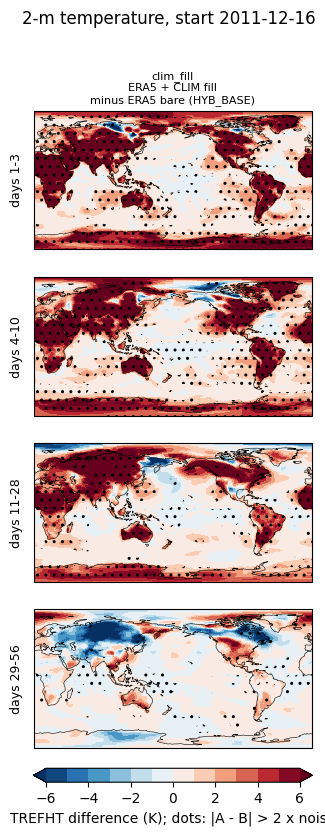

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_T850.png


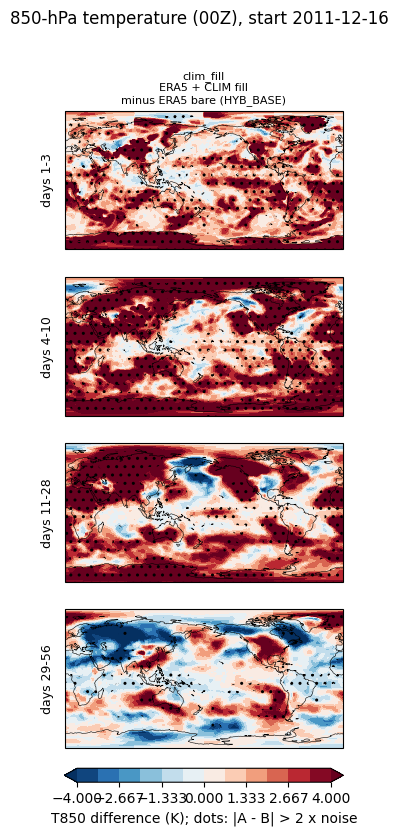

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_TOZ.png


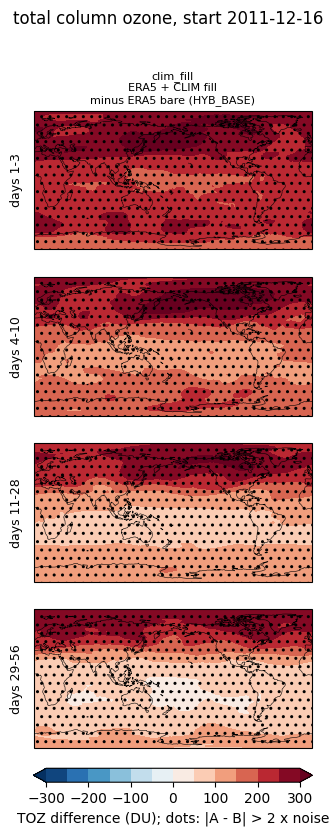

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_FSDSC.png


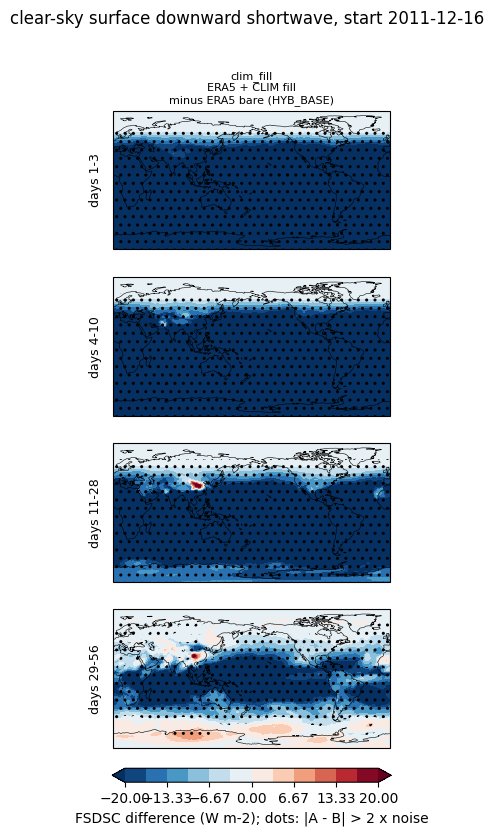

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_FLDS.png


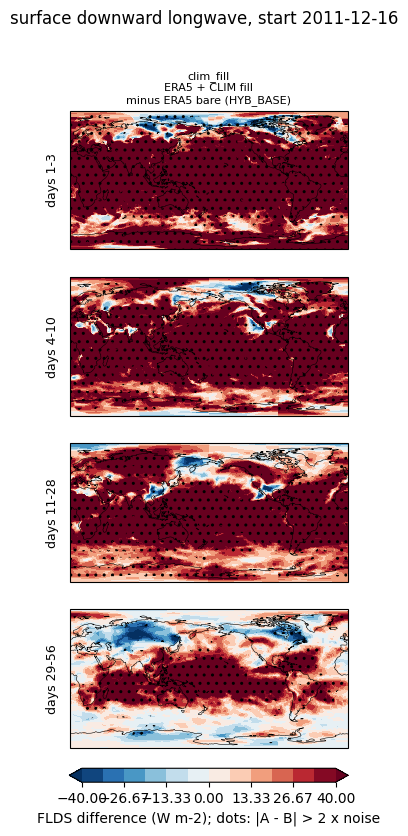

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_SWCF.png


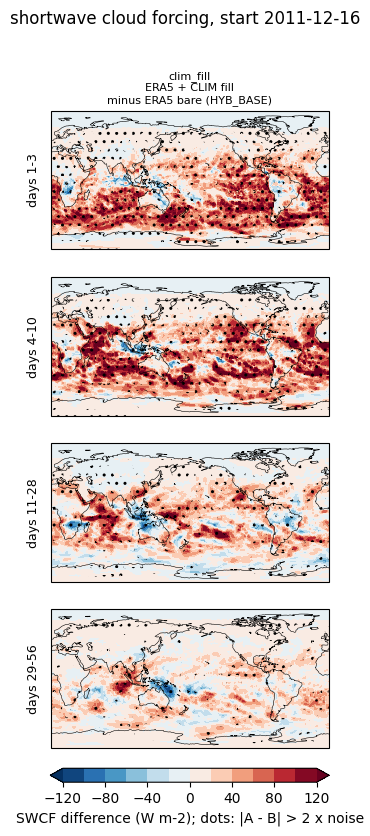

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_LWCF.png


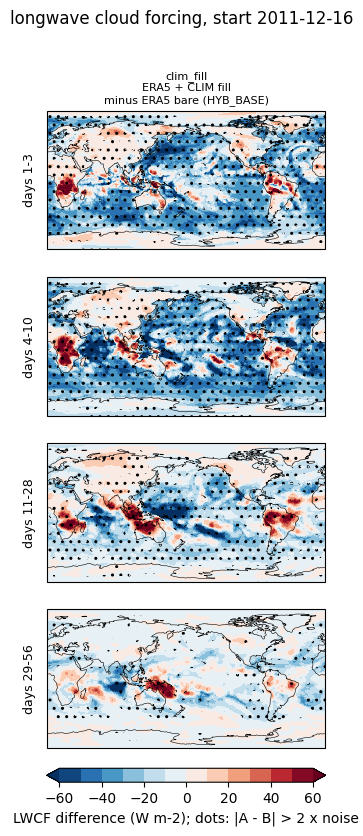

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_PRECT.png


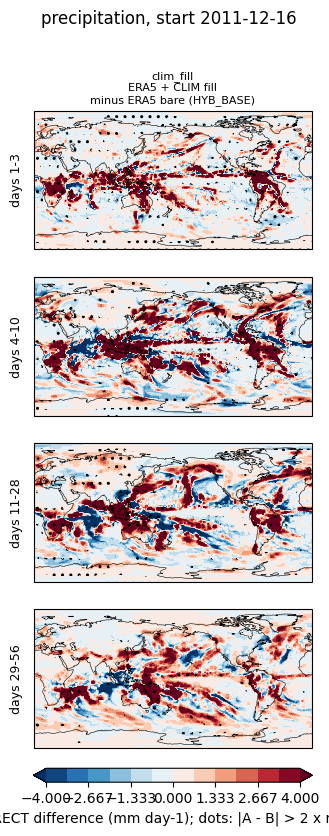

In [5]:
def plot_maps(ds, lim=None, name=None):
    v = ds.attrs["variable"]
    lim = lim or float(np.nanpercentile(np.abs(ds["difference"]), 98))
    levels = np.linspace(-lim, lim, 13)
    windows = list(ds.window.values)
    nr, nc = len(windows), len(COMPARISON_KEYS)
    fig, axes = plt.subplots(nr, nc, figsize=(3.6 * nc, 2.0 * nr + 0.8),
                             subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)), squeeze=False)
    for j, c in enumerate(COMPARISON_KEYS):
        a, b, _ = COMPARISONS[c]
        for i, w in enumerate(windows):
            ax = axes[i, j]
            d = ds["difference"].sel(comparison=c, window=w)
            cf = ax.contourf(d.lon, d.lat, d, levels=levels, cmap="RdBu_r", extend="both", transform=ccrs.PlateCarree())
            sig = (np.abs(d) > 2 * ds["noise"].sel(window=w)).astype(float)
            ax.contourf(d.lon, d.lat, sig, levels=[0.5, 1.5], hatches=[".."], colors="none", transform=ccrs.PlateCarree())
            ax.coastlines(lw=0.4)
            if i == 0:
                ax.set_title(f"{c}\n{RUNS[a].label}\nminus {RUNS[b].label}", fontsize=8)
            if j == 0:
                ax.text(-0.04, 0.5, w, transform=ax.transAxes, rotation=90, ha="right", va="center", fontsize=9)
    fig.colorbar(cf, ax=axes, orientation="horizontal", fraction=0.03, pad=0.03,
                 label=f"{v} difference ({ds.attrs['units']}); dots: |A - B| > 2 x noise")
    fig.suptitle(f"{ds.attrs['long_name']}, start {INIT}", y=0.995)
    save(fig, name or f"maps_{v}.png")
    plt.show()


for v in VARIABLES:
    plot_maps(maps[v], LIMITS.get(v))

## 6. Monthly ozone, CO and aerosol fields (`eam.h0`)

O3, CO and the aerosol optical depth are written only to the monthly `eam.h0` files on the native ne30pg2 grid; CH4LNZ is in no history stream. The first h0 file of each run averages the start date to the end of December (lead days 1-16), the second one January (days 17-47). The fields are remapped to 1° with the aave weights of `regen_f20tr_ts.sh` (`ATM_MAP_FILE`). The noise scale is √2 × the spread of the 20 HYB_BASE members in the same calendar month, as above.

- `O3_SRF`, `CO_SRF`: mixing ratio in the bottom model layer (ppbv); `AODVIS`: aerosol optical depth at 550 nm.
- `O3`: zonal mean on the model levels (reference pressure), shown as 100 × (A − B) / A, so that the stratosphere and troposphere share one scale: +100 % means run B has none of run A's ozone. Grey contours: run A's zonal-mean O3 (100, 1000, 3000, 6000, 9000 ppbv).

In [6]:
regrid = ev.AaveMap(ATM_MAP_FILE)
h0_stamp = "|".join(["v2", ",".join(f"{k}={paths[k]}" for k in RUN_KEYS), ",".join(ens_members), ",".join(COMPARISON_KEYS),
                     str(ATM_MAP_FILE)])


def build_h0(v):
    win = {k: ev.open_h0(paths[k], INIT, v, regrid) for k in {x for c in COMPARISON_KEYS for x in COMPARISONS[c][:2]}}
    ens = xr.concat([ev.open_h0(member_dir(ENSEMBLE_RUN, ROOTS).parent / m, INIT, v, regrid) for m in ens_members],
                    pd.Index(ens_members, name="member"))
    diff = xr.concat([win[COMPARISONS[c][0]] - win[COMPARISONS[c][1]] for c in COMPARISON_KEYS],
                     pd.Index(list(COMPARISON_KEYS), name="comparison"))
    run_a = xr.concat([win[COMPARISONS[c][0]] for c in COMPARISON_KEYS], pd.Index(list(COMPARISON_KEYS), name="comparison"))
    ds = xr.Dataset({"difference": diff, "noise": ev.noise_scale(ens), "run_a": run_a, "ensemble_mean": ens.mean("member")})
    s = ev.H0_VARIABLES[v]
    ds.attrs.update(variable=v, units=s.units, long_name=f"{s.long_name} (monthly eam.h0)", ensemble_run=ENSEMBLE_RUN)
    return ds


h0_maps = {v: cached_dataset(data_dir / f"h0_maps_{v}.nc", lambda v=v: build_h0(v), h0_stamp, force=FORCE_COMPUTE)
           for v in H0_VARIABLES}
display(pd.DataFrame({v: ds["difference"].weighted(np.cos(np.deg2rad(ds.lat))).mean([d for d in ds["difference"].dims
                                                                                      if d in ("lat", "lon")]).to_series()
                      for v, ds in h0_maps.items() if not ev.H0_VARIABLES[v].zonal}).rename_axis(columns="global-mean difference"))

[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_O3.nc: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_O3.nc
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_O3_SRF.nc: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_O3_SRF.nc
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_CO_SRF.nc: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_CO_SRF.nc
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_AODVIS.nc: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/maps/h0_maps_AODVIS.nc


global-mean difference               O3_SRF     CO_SRF    AODVIS
comparison window                                               
clim_fill  days 1-16 (Dec 2011)   25.963760  69.362068  0.069636
           days 17-47 (Jan 2012)  23.840718  56.551926  0.045312

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/zonal_O3_monthly.png


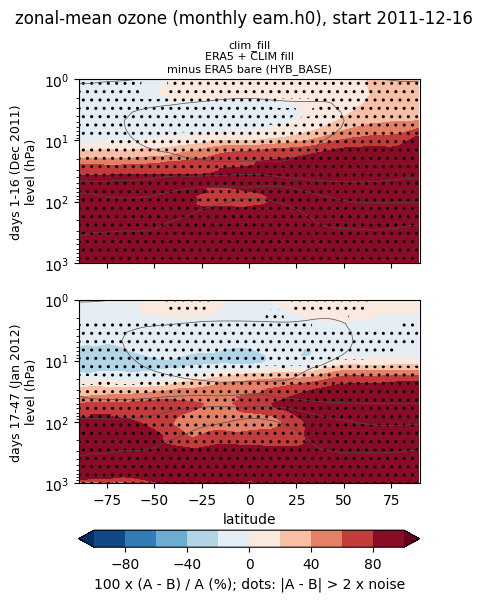

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_O3_SRF_monthly.png


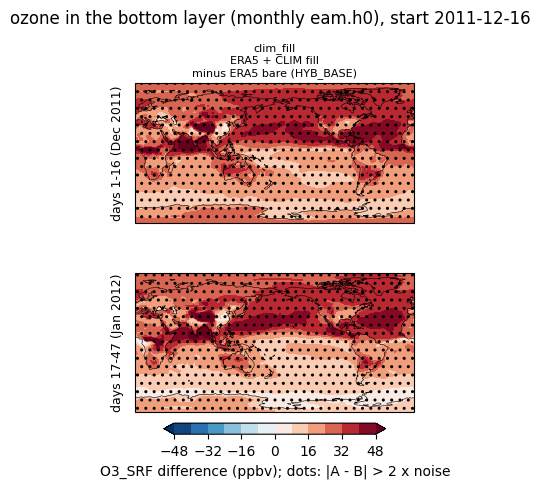

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_CO_SRF_monthly.png


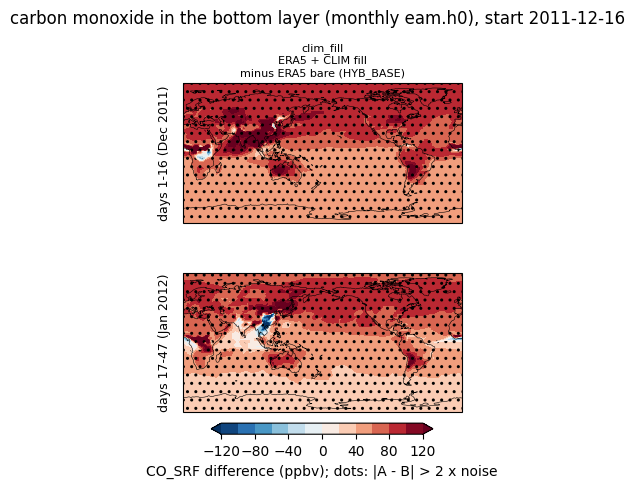

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/maps/maps_AODVIS_monthly.png


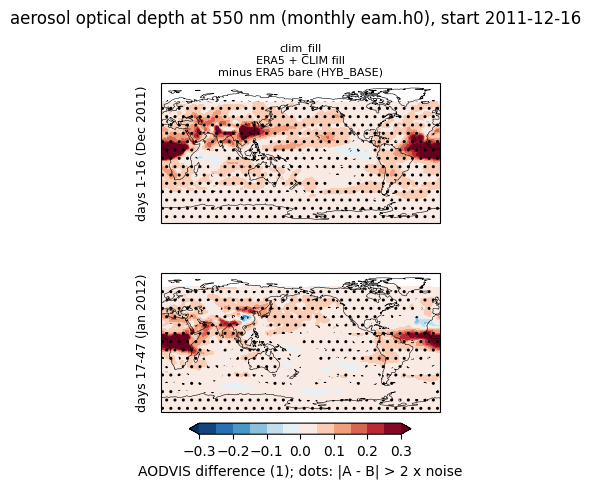

In [7]:
def plot_zonal_section(ds, lim):
    """Latitude-level section of the zonal-mean difference, 100 x (A - B) / A."""
    v = ds.attrs["variable"]
    windows = list(ds.window.values)
    levels = np.linspace(-lim, lim, 11)
    nr, nc = len(windows), len(COMPARISON_KEYS)
    fig, axes = plt.subplots(nr, nc, figsize=(4.4 * nc, 2.6 * nr + 0.9), squeeze=False, sharex=True, sharey=True)
    for j, c in enumerate(COMPARISON_KEYS):
        a, b, _ = COMPARISONS[c]
        for i, w in enumerate(windows):
            ax = axes[i, j]
            d = ds["difference"].sel(comparison=c, window=w)
            ref = ds["run_a"].sel(comparison=c, window=w)
            pct = 100 * d / ref.where(ref > 0)
            cf = ax.contourf(d.lat, d.lev, pct, levels=levels, cmap="RdBu_r", extend="both")
            sig = (np.abs(d) > 2 * ds["noise"].sel(window=w)).astype(float)
            ax.contourf(d.lat, d.lev, sig, levels=[0.5, 1.5], hatches=[".."], colors="none")
            ax.contour(d.lat, d.lev, ref, levels=[100, 1000, 3000, 6000, 9000], colors="0.3", linewidths=0.5)
            ax.set_yscale("log")
            ax.set_ylim(1000, 1)
            ax.set_xlim(-90, 90)
            if i == 0:
                ax.set_title(f"{c}\n{RUNS[a].label}\nminus {RUNS[b].label}", fontsize=8)
            if j == 0:
                ax.set_ylabel(f"{w}\nlevel (hPa)", fontsize=9)
            if i == nr - 1:
                ax.set_xlabel("latitude")
    fig.colorbar(cf, ax=axes, orientation="horizontal", fraction=0.04, pad=0.1,
                 label=f"100 x (A - B) / A (%); dots: |A - B| > 2 x noise")
    fig.suptitle(f"zonal-mean {ds.attrs['long_name']}, start {INIT}", y=0.995)
    save(fig, f"zonal_{v}_monthly.png")
    plt.show()


for v in H0_VARIABLES:
    if ev.H0_VARIABLES[v].zonal:
        plot_zonal_section(h0_maps[v], H0_LIMITS.get(v, 50.0))
    else:
        plot_maps(h0_maps[v], H0_LIMITS.get(v), f"maps_{v}_monthly.png")